# From raw Terraform code to research conclusions

This notebook walks through exactly how the Lock-In Index (LII) paper reached its results. It follows one real configuration from raw code to a score, then the whole dataset to each research question (RQ1–RQ4).

**Run it:** open this folder in VS Code (Jupyter extension) or run `jupyter notebook`, then *Run All*. It reads the files produced by `run_all.sh` in `../results` and the raw code in `../data`.

In [1]:
import csv, json, re, math, statistics
from collections import Counter, defaultdict
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path("..")
RULES = json.load(open(ROOT / "results" / "rules.json"))
W = RULES["weights"]                       # [0.35, 0.25, 0.25, 0.15] for A, D, E, X
CATS = {k: tuple(v) for k, v in RULES["categories"].items()}
PATTERNS = [(c, re.compile(p)) for c, p in RULES["rules"]]
print("weights (A, D, E, X):", W)
print("categories:", len(CATS), "| classification rules:", len(PATTERNS))

weights (A, D, E, X): [0.35, 0.25, 0.25, 0.15]
categories: 21 | classification rules: 18


## Step 1 · The raw input: one real Terraform file

This is `main.tf` from the AWS **serverless-patterns** repository (folder `dynamodb-streams-lambda-terraform`), one of the 677 configurations we analysed. It builds a DynamoDB table whose changes trigger a Lambda function.

In [2]:
tf_file = ROOT / "data/terraform_sources/aws-samples_serverless-patterns/dynamodb-streams-lambda-terraform/main.tf"
text = tf_file.read_text()
print("\n".join(text.splitlines()[:60]))

terraform {
  required_providers {
    aws = {
      source  = "hashicorp/aws"
      version = "~> 5.0"
    }
  }

  required_version = ">= 0.14.9"
}

provider "aws" {
  profile = "default"
  region  = "us-east-1"
}

resource "aws_dynamodb_table" "dynamodb_table_users" {
  name             = "UsersIds"
  billing_mode     = "PROVISIONED"
  read_capacity    = 5
  write_capacity   = 5
  stream_enabled   = true
  stream_view_type = "NEW_AND_OLD_IMAGES"
  hash_key         = "UserId"

  attribute {
    name = "UserId"
    type = "S"
  }

  tags = {
    Name        = "dynamodb-test-table"
    Environment = "dev"
  }
}

resource "aws_lambda_function" "lambda_dynamodb_stream_handler" {
  function_name    = "process-usersids-records"
  filename         = data.archive_file.lambda_zip_file.output_path
  source_code_hash = data.archive_file.lambda_zip_file.output_base64sha256
  handler          = "index.handler"
  role             = aws_iam_role.iam_for_lambda.arn
  runtime          = "nodejs24.x"


## Step 2 · Extract the resources

Every cloud resource in Terraform is declared as `resource "TYPE" "NAME"`. The analyzer finds them with one regular expression (the same one used in `src/lii.py`).

In [3]:
RES_RE = re.compile(r'^\s*resource\s+"([A-Za-z0-9_\-]+)"\s+"[^"]+"', re.M)
types = RES_RE.findall(text)
types

['aws_dynamodb_table',
 'aws_lambda_function',
 'aws_lambda_event_source_mapping',
 'aws_iam_role',
 'aws_iam_role_policy']

## Step 3 · Classify each resource

The provider comes from the prefix (`aws_` → AWS). The service category comes from an ordered list of pattern rules: the first rule that matches wins.

In [4]:
UTIL = set(RULES["utility"])
def provider_of(t):
    p = t.split("_", 1)[0]
    if p in ("aws", "awscc"): return "AWS"
    if p in ("azurerm", "azuread", "azapi"): return "Azure"
    if p == "google": return "GCP"
    if p in ("kubernetes", "kubectl", "helm"): return "K8s"
    return "utility" if p in UTIL else "other"

def categorise(t):
    prov = provider_of(t)
    if prov == "K8s": return "Kubernetes-native"
    if t.startswith("azapi_"): return "Raw ARM API (azapi)"
    if prov == "Azure" and t.startswith("azuread_"): return "IAM/identity"
    body = t.split("_", 1)[1] if "_" in t else t
    body = body[5:] if body.startswith("beta_") else body
    for cat, rx in PATTERNS:
        if rx.search(body): return cat
    return "Other provider"

pd.DataFrame([(t, provider_of(t), categorise(t)) for t in types], columns=["resource type", "provider", "category"])

,resource type,provider,category
0,aws_dynamodb_table,AWS,Proprietary NoSQL
1,aws_lambda_function,AWS,Serverless functions
2,aws_lambda_event_source_mapping,AWS,Serverless functions
3,aws_iam_role,AWS,IAM/identity
4,aws_iam_role_policy,AWS,IAM/identity


## Step 4 · Score each resource (Equation 1)

Each category has four rubric scores between 0 and 1: **A** API proprietariness, **D** data/state lock, **E** equivalence gap, **X** egress exposure.

$$\mathrm{LII}(r) = 0.35A + 0.25D + 0.25E + 0.15X$$

In [5]:
def resource_lii(cat):
    a, d, e, x = CATS[cat]
    return W[0]*a + W[1]*d + W[2]*e + W[3]*x

rows = []
for t in types:
    cat = categorise(t); a, d, e, x = CATS[cat]
    rows.append(dict(type=t, category=cat, A=a, D=d, E=e, X=x,
                     working=f"0.35×{a} + 0.25×{d} + 0.25×{e} + 0.15×{x}", score=round(100*resource_lii(cat), 1)))
pd.DataFrame(rows)

,type,category,A,D,E,X,working,score
0,aws_dynamodb_table,Proprietary NoSQL,0.9,0.8,0.7,0.8,0.35×0.9 + 0.25×0.8 + 0.25×0.7 + 0.15×0.8,81.0
1,aws_lambda_function,Serverless functions,0.8,0.1,0.4,0.0,0.35×0.8 + 0.25×0.1 + 0.25×0.4 + 0.15×0.0,40.5
2,aws_lambda_event_source_mapping,Serverless functions,0.8,0.1,0.4,0.0,0.35×0.8 + 0.25×0.1 + 0.25×0.4 + 0.15×0.0,40.5
3,aws_iam_role,IAM/identity,0.9,0.0,0.5,0.0,0.35×0.9 + 0.25×0.0 + 0.25×0.5 + 0.15×0.0,44.0
4,aws_iam_role_policy,IAM/identity,0.9,0.0,0.5,0.0,0.35×0.9 + 0.25×0.0 + 0.25×0.5 + 0.15×0.0,44.0


## Step 5 · Score the configuration (Equation 2)

The configuration's LII is the **average** of its resource scores, times 100. We use the average so that big configurations aren't penalised just for being big.

In [6]:
scores = [r["score"] for r in rows]
lii = sum(scores) / len(scores)
print(" + ".join(map(str, scores)), f"= {sum(scores):.1f}")
print(f"LII = {sum(scores):.1f} / {len(scores)} = {lii:.1f}")

cfg = pd.read_csv(ROOT / "results/tables/configurations.csv")
cfg[cfg.path == "dynamodb-streams-lambda-terraform"][["config_id", "repository", "path", "n_resources", "lii"]]

81.0 + 40.5 + 40.5 + 44.0 + 44.0 = 250.0
LII = 250.0 / 5 = 50.0


,config_id,repository,path,n_resources,lii
63,C0064,aws-samples/serverless-patterns,dynamodb-streams-lambda-terraform,5,50.0


## Step 6 · The whole dataset

`src/lii.py` repeats steps 1–5 for every root configuration in `data/terraform_sources` (following local modules too). Configurations with fewer than 3 cloud resources are skipped.

In [7]:
res = pd.read_csv(ROOT / "results/tables/resources.csv")
print(f"{len(cfg)} configurations, {len(res)} resource declarations, {res.resource_type.nunique()} distinct types, "
      f"{cfg.repository.nunique()} repositories")
print(f"unclassified: {100*(res.category == 'Other provider').mean():.1f}%   median size: {cfg.n_resources.median():.0f} resources")
cfg.groupby("provider").size().rename("configurations").to_frame()

677 configurations, 8908 resource declarations, 844 distinct types, 23 repositories
unclassified: 1.3%   median size: 6 resources


,configurations
provider,
AWS,191
Azure,248
GCP,238


## RQ1 · How is lock-in distributed across providers?

,count,mean,25%,50%,75%,min,max
provider,,,,,,,
AWS,191.0,38.6,34.1,41.5,44.4,19.0,54.8
Azure,248.0,31.1,24.2,27.2,37.3,20.8,52.4
GCP,238.0,31.8,23.6,28.6,38.5,9.1,77.5


Overall mean LII 33.5; 27.2% of configurations score above 40.
AWS median without the 90 serverless-patterns configs: 36.7  -> the AWS difference is a sampling effect.


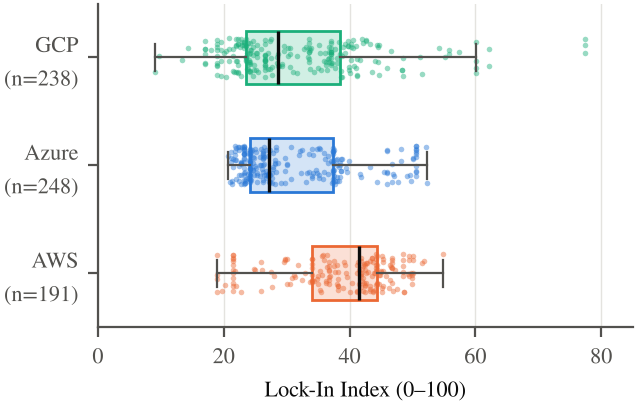

In [8]:
t = cfg.groupby("provider").lii.describe()[["count", "mean", "25%", "50%", "75%", "min", "max"]].round(1)
display(t)
aws_wo_sp = cfg[(cfg.provider == "AWS") & ~cfg.repository.str.contains("serverless-patterns")].lii.median()
print(f"Overall mean LII {cfg.lii.mean():.1f}; {100*(cfg.lii > 40).mean():.1f}% of configurations score above 40.")
print(f"AWS median without the 90 serverless-patterns configs: {aws_wo_sp:.1f}  -> the AWS difference is a sampling effect.")
display(Image(ROOT / "figures/fig_provider.png", width=600))

## RQ2 · Which service categories drive lock-in?

**Lock-in mass** of a category = sum of its resource scores over the whole dataset. Its share of the total shows how much lock-in it is responsible for.

,resources,share_of_resources_%,share_of_lockin_%
category,,,
IAM/identity,1480,16.6,21.1
Network core,2497,28.0,15.4
Raw ARM API (azapi),685,7.7,11.2
Governance/org,685,7.7,8.4
Analytics/AI,243,2.7,6.1
Object storage,462,5.2,5.1
Messaging/eventing,269,3.0,4.2
Observability,335,3.8,4.2
API/workflow,246,2.8,4.1


Glue categories: 59.7% of resources, 52.7% of lock-in


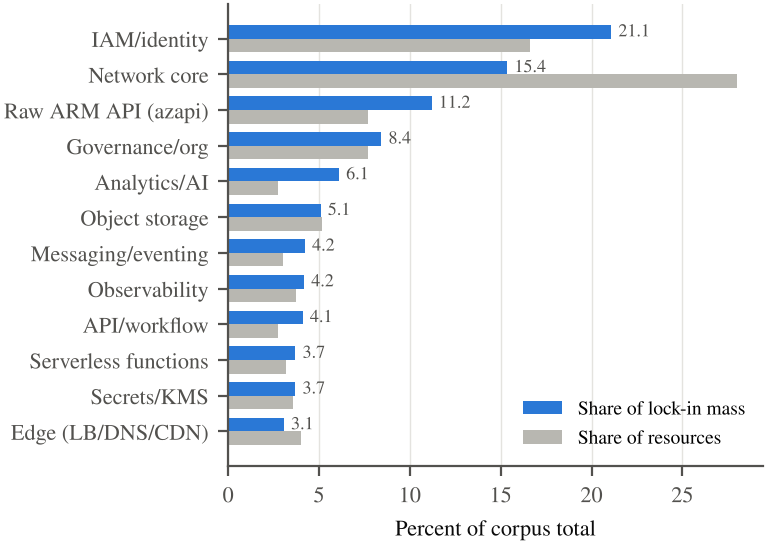

In [9]:
GLUE = ["IAM/identity", "Network core", "Governance/org", "Secrets/KMS", "Observability"]
by = res.groupby("category").agg(resources=("resource_lii", "size"), mass=("resource_lii", "sum"))
by["share_of_resources_%"] = (100 * by.resources / by.resources.sum()).round(1)
by["share_of_lockin_%"] = (100 * by.mass / by.mass.sum()).round(1)
display(by.sort_values("mass", ascending=False).drop(columns="mass").head(12))
g = by.loc[GLUE]
print(f"Glue categories: {100*g.resources.sum()/by.resources.sum():.1f}% of resources, {100*g.mass.sum()/by.mass.sum():.1f}% of lock-in")
display(Image(ROOT / "figures/fig_categories.png", width=600))

## RQ3 · Does the index separate architectural styles?

Kubernetes-centric = uses Kubernetes and no proprietary PaaS. Managed-PaaS-centric = uses serverless, proprietary NoSQL, API/workflow or proprietary containers, and no Kubernetes. We compare them with the **Mann–Whitney U test** (do values in one group tend to be smaller?) and **Cliff's δ** (how big is the difference?).

,count,median,mean
architecture_group,,,
IaaS/other,457,27.1,31.5
K8s-centric,47,25.2,26.2
Managed-PaaS-centric,173,41.9,40.8


U = 642.0, z = -8.85, p = 9.0e-19, Cliff's delta = -0.84
-> pick one config from each group: the Kubernetes one is lower about 92% of the time


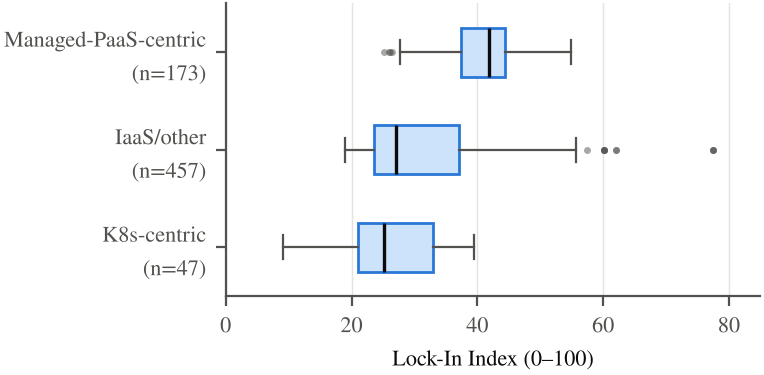

In [10]:
def mann_whitney(a, b):
    allv = sorted([(v, 0) for v in a] + [(v, 1) for v in b]); rk = [0.0]*len(allv); i = 0
    while i < len(allv):
        j = i
        while j + 1 < len(allv) and allv[j+1][0] == allv[i][0]: j += 1
        for k in range(i, j+1): rk[k] = (i + j)/2 + 1
        i = j + 1
    n1, n2 = len(a), len(b); u = sum(r for r, (v, g) in zip(rk, allv) if g == 0) - n1*(n1+1)/2
    z = (u - n1*n2/2) / math.sqrt(n1*n2*(n1+n2+1)/12)
    return u, z, math.erfc(abs(z)/math.sqrt(2)), 2*u/(n1*n2) - 1

display(cfg.groupby("architecture_group").lii.agg(["count", "median", "mean"]).round(1))
k8s = cfg[cfg.architecture_group == "K8s-centric"].lii.tolist()
paas = cfg[cfg.architecture_group == "Managed-PaaS-centric"].lii.tolist()
u, z, p, d = mann_whitney(k8s, paas)
print(f"U = {u:.1f}, z = {z:.2f}, p = {p:.1e}, Cliff's delta = {d:.2f}")
print(f"-> pick one config from each group: the Kubernetes one is lower about {50*(1-d):.0f}% of the time")
display(Image(ROOT / "figures/fig_groups.png", width=600))

## RQ4 · Do the results depend on our exact rubric?

`src/lii.py` re-scored everything 1,000 times with random weights and every category score shifted by up to ±0.15 (seed 42), and compared each new ranking with the original using Spearman's ρ.

configuration ranking: median rho 0.91, 5th percentile 0.71
category ranking:      median rho 0.97
Kubernetes group lower than PaaS group in 99.7% of trials


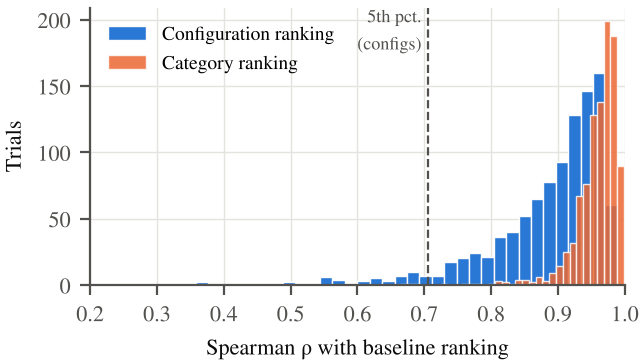

In [11]:
sens = pd.read_csv(ROOT / "results/tables/sensitivity_trials.csv")
R = json.load(open(ROOT / "results/results.json"))
print(f"configuration ranking: median rho {sens.spearman_config_ranking.median():.2f}, 5th percentile {sens.spearman_config_ranking.quantile(0.05):.2f}")
print(f"category ranking:      median rho {sens.spearman_category_ranking.median():.2f}")
print(f"Kubernetes group lower than PaaS group in {100*R['rq4']['k8s_lower_share']:.1f}% of trials")
display(Image(ROOT / "figures/fig_sensitivity.png", width=600))

## Exit cost · What does it cost to move data out?

,volume_GB,AWS_usd,Azure_usd,GCP_usd
0,1000,81,76,120
1,10000,891,842,1110
2,100000,7812,6696,8317
3,1000000,53886,48268,80317


AWS, 10 TB: (10,000 GB − 100 GB free) × $0.09 = 891.0


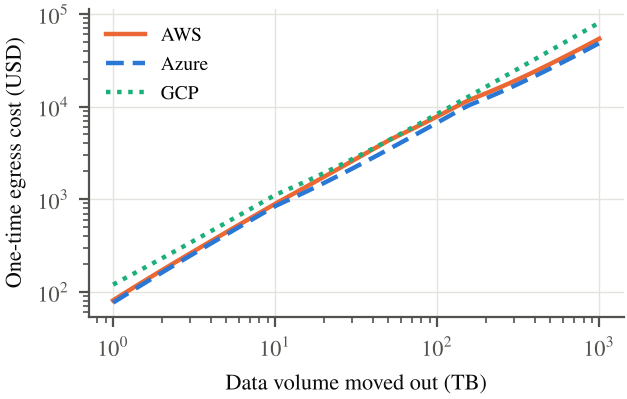

In [12]:
display(pd.read_csv(ROOT / "results/tables/egress_exit_cost.csv"))
print("AWS, 10 TB: (10,000 GB − 100 GB free) × $0.09 =", (10000 - 100) * 0.09)
display(Image(ROOT / "figures/fig_egress.png", width=600))

## Summary: from data to conclusions

| Research question | Evidence (computed above) | Conclusion in the paper |
|---|---|---|
| RQ1 | AWS median higher, but driven by the serverless-heavy sample | Differences reflect what the code builds, not the provider |
| RQ2 | IAM ≈ 21% of lock-in; glue ≈ 53% of lock-in | Lock-in sits in the scaffolding, IAM first |
| RQ3 | Median 25.2 vs 41.9, Cliff's δ = −0.84 | Kubernetes-centric designs are much less locked-in (not lock-in free) |
| RQ4 | Median ρ = 0.91 over 1,000 random rubrics | Conclusions don't depend on our exact rubric values |

`src/verify_against_paper.py` checks all 36 numbers quoted in the paper against these results (see `results/verification.txt`).